# Decision Tree Regression on Dataset2 (portuguese Class)

$\textit{by Ashmi sharma (MS24022)}$

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load dataset
df = pd.read_csv("student-por.csv", sep=";")

print("Dataset shape:", df.shape)
print(df.head())
print(df.info())

Dataset shape: (649, 33)
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]
<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Da

In [2]:
# Selected candidate features
selected_columns = [
    "G1",
    "G2",
    "studytime",
    "failures",
    "absences",
    "age",
    "Medu",
    "Fedu",
    "schoolsup",
    "higher"
]

# Input variables
X = df[selected_columns]

# Target variable
y = df["G3"]

print("Input features:", X.columns.tolist())
print("Number of input features:", X.shape[1])

Input features: ['G1', 'G2', 'studytime', 'failures', 'absences', 'age', 'Medu', 'Fedu', 'schoolsup', 'higher']
Number of input features: 10


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (519, 10)
Testing data: (130, 10)


In [4]:
numerical_features = [
    "G1", "G2", "studytime", "failures",
    "absences", "age", "Medu", "Fedu"
]

categorical_features = [
    "schoolsup", "higher"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),

        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

In [5]:
selector = SelectFromModel(
    estimator=ExtraTreesRegressor(
        n_estimators=200,
        random_state=42
    ),
    threshold=-np.inf,
    max_features=8
)

In [6]:
dt = DecisionTreeRegressor(random_state=42)

pipeline = Pipeline([
    ("preprocessing", preprocessor),

    ("feature_selection", selector),

    ("regressor", dt)
])

In [7]:
param_grid = {
    "regressor__max_depth": [2, 3, 4, 5, 6, 8, 10, None],

    "regressor__min_samples_split": [2, 5, 10, 15],

    "regressor__min_samples_leaf": [1, 2, 4, 6]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# Train
grid_search.fit(X_train, y_train)

# Best model
best_model = grid_search.best_estimator_

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest CV RMSE:")
print(np.sqrt(-grid_search.best_score_))

Best parameters:
{'regressor__max_depth': 5, 'regressor__min_samples_leaf': 6, 'regressor__min_samples_split': 2}

Best CV RMSE:
1.2757898240961694


In [8]:
# Feature names after encoding
feature_names = (
    best_model.named_steps["preprocessing"]
    .get_feature_names_out()
)

# Selected feature mask
mask = (
    best_model.named_steps["feature_selection"]
    .get_support()
)

# Selected features
final_features = feature_names[mask]

print("Final number of features:", len(final_features))

print("\nRelevant features selected by model:")

for f in final_features:
    print(f)

Final number of features: 8

Relevant features selected by model:
num__G1
num__G2
num__studytime
num__failures
num__absences
num__age
num__Medu
num__Fedu


In [9]:
y_train_pred = best_model.predict(X_train)

y_test_pred = best_model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [10]:
# Training metrics
train_mae = mean_absolute_error(y_train, y_train_pred)

train_mse = mean_squared_error(y_train, y_train_pred)

train_rmse = np.sqrt(train_mse)

train_r2 = r2_score(y_train, y_train_pred)


# Testing metrics
test_mae = mean_absolute_error(y_test, y_test_pred)

test_mse = mean_squared_error(y_test, y_test_pred)

test_rmse = np.sqrt(test_mse)

test_r2 = r2_score(y_test, y_test_pred)


# Results table
results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2 Score"],

    "Training": [
        train_mae, train_mse, train_rmse, train_r2
    ],

    "Testing": [
        test_mae, test_mse, test_rmse, test_r2
    ]
})

print(results)

     Metric  Training   Testing
0       MAE  0.737620  0.793140
1       MSE  1.291048  1.852620
2      RMSE  1.136243  1.361110
3  R2 Score  0.877346  0.810021


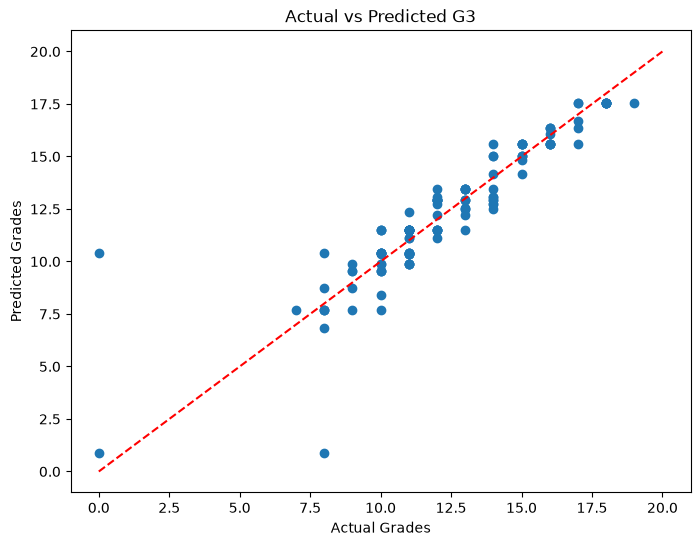

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred)

plt.plot([0, 20], [0, 20], "r--")

plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")

plt.title("Actual vs Predicted G3")

plt.show()

          Feature  Importance
1         num__G2    0.951006
4   num__absences    0.016960
5        num__age    0.013456
0         num__G1    0.007732
3   num__failures    0.004761
7       num__Fedu    0.003877
2  num__studytime    0.001143
6       num__Medu    0.001066


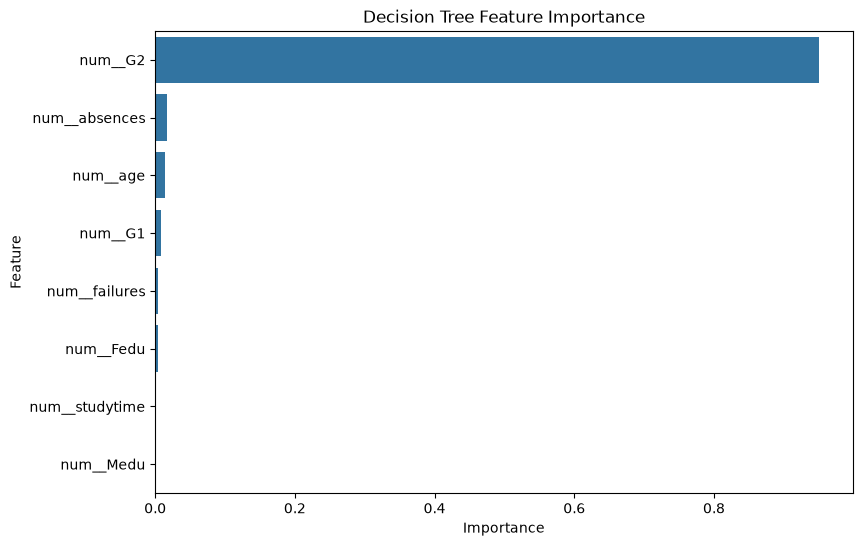

In [12]:
importance = (
    best_model.named_steps["regressor"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": final_features,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree Feature Importance")
plt.show()

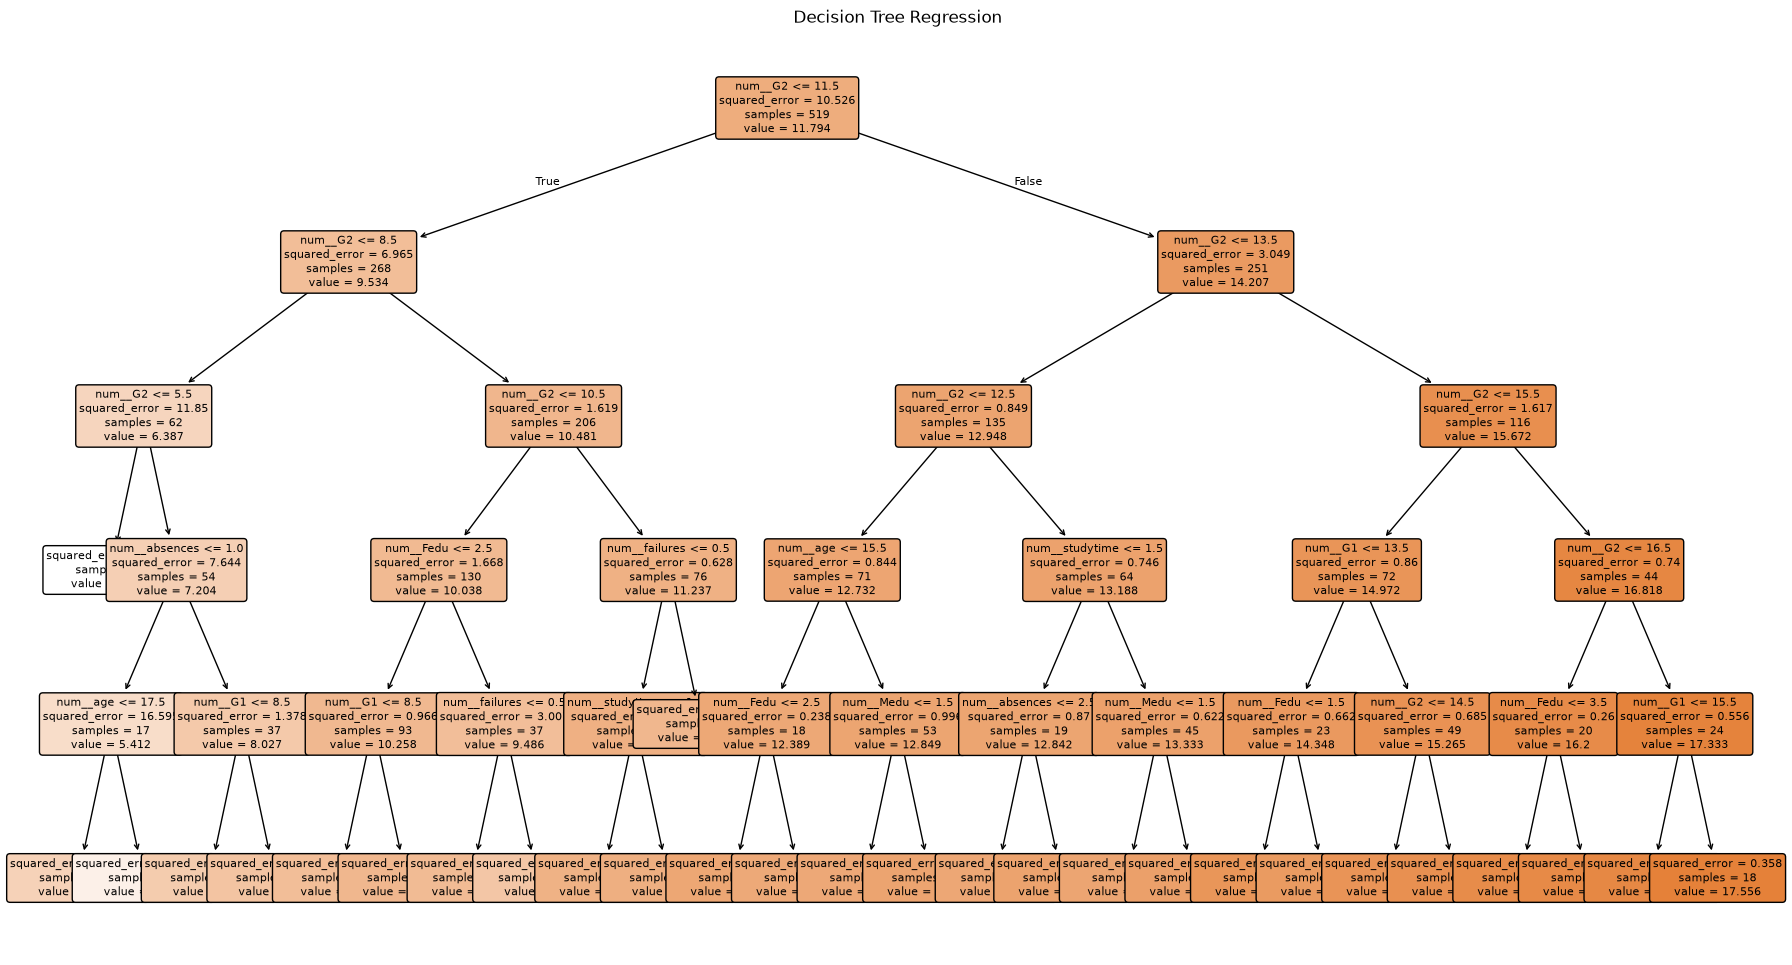

In [13]:
plt.figure(figsize=(22, 12))

plot_tree(
    best_model.named_steps["regressor"],
    feature_names=final_features,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Regression")
plt.show()